# Cell 1 — Imports, GPU and load Donut

In [2]:
import os
import math
import time
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import tqdm
from transformers import DonutProcessor, VisionEncoderDecoderModel
from transformers.models.bart.modeling_bart import shift_tokens_right

os.environ["TOKENIZERS_PARALLELISM"] = "false"

assert torch.cuda.is_available(), "GPU is not enabled!"
print("GPU:", torch.cuda.get_device_name(0))

DATA_ROOT = "/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset"
MODEL_NAME = "naver-clova-ix/donut-base"

processor = DonutProcessor.from_pretrained(MODEL_NAME)
donut = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

print("Encoder:", type(donut.encoder).__name__)
print("Decoder:", type(donut.decoder).__name__)
print("Tokenizer size:", len(processor.tokenizer))
print("Donut loaded successfully")

GPU: Tesla T4


preprocessor_config.json:   0%|          | 0.00/362 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/518 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/4.01M [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/484 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  809MB            

model.safetensors: downloading bytes:           |  0.00B            

Encoder: DonutSwinModel
Decoder: MBartForCausalLM
Tokenizer size: 57525
Donut loaded successfully


# Cell 2 — Create image–CSV dataset

In [4]:
class ChartQATableDataset(Dataset):
    def __init__(self, root, split, processor, max_target_length=512):
        self.split_dir = os.path.join(root, split)
        self.processor = processor
        self.tokenizer = processor.tokenizer
        self.max_target_length = max_target_length

        png_dir = os.path.join(self.split_dir, "png")
        csv_dir = os.path.join(self.split_dir, "tables")

        images = {
            os.path.splitext(f)[0]: f
            for f in os.listdir(png_dir)
            if f.lower().endswith(".png")
        }
        tables = {
            os.path.splitext(f)[0]: f
            for f in os.listdir(csv_dir)
            if f.lower().endswith(".csv")
        }

        common = sorted(images.keys() & tables.keys())
        assert common, f"No matching image/CSV pairs in {split}"

        self.samples = [
            (
                os.path.join(png_dir, images[k]),
                os.path.join(csv_dir, tables[k])
            )
            for k in common
        ]

        print(f"{split}: {len(self.samples)} image-table pairs")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, csv_path = self.samples[idx]

        with Image.open(image_path) as im:
            pixel_values = self.processor(
                im.convert("RGB"),
                return_tensors="pt"
            ).pixel_values.squeeze(0)

        df = pd.read_csv(csv_path).fillna("")

        header = " | ".join(str(c) for c in df.columns)
        rows = [
            " | ".join(str(v) for v in row)
            for row in df.itertuples(index=False, name=None)
        ]

        target = header
        if rows:
            target += " [ROW] " + " [ROW] ".join(rows)

        labels = self.tokenizer(
            target,
            max_length=self.max_target_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        ).input_ids.squeeze(0)

        labels[labels == self.tokenizer.pad_token_id] = -100

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }


train_dataset = ChartQATableDataset(
    DATA_ROOT, "train", processor
)
val_dataset = ChartQATableDataset(
    DATA_ROOT, "val", processor
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

train: 18317 image-table pairs
val: 1056 image-table pairs
Train: 18317
Validation: 1056


# Cell 3 — Verify data and decoder configuration

In [5]:
sample = train_dataset[0]

print("Image tensor:", sample["pixel_values"].shape)
print("Label tensor:", sample["labels"].shape)
print("Pad token:", processor.tokenizer.pad_token_id)
print("BOS token:", processor.tokenizer.bos_token_id)
print("EOS token:", processor.tokenizer.eos_token_id)
print("Decoder vocab:", donut.decoder.config.vocab_size)
print("Tokenizer vocab:", len(processor.tokenizer))
print("Decoder is decoder:", donut.decoder.config.is_decoder)
print("Cross-attention:", donut.decoder.config.add_cross_attention)

assert donut.decoder.config.vocab_size == len(processor.tokenizer)
assert donut.decoder.config.add_cross_attention, (
    "Decoder cross-attention is not enabled; stop before training."
)

print("Data and decoder checks passed.")

Image tensor: torch.Size([3, 2560, 1920])
Label tensor: torch.Size([512])
Pad token: 1
BOS token: 0
EOS token: 2
Decoder vocab: 57525
Tokenizer vocab: 57525
Decoder is decoder: True
Cross-attention: True
Data and decoder checks passed.


# Cell 4 — Run Claude's v2 pilot

In [6]:
import torch.nn as nn

class DonutPretrainedDecoderModel(nn.Module):
    def __init__(self, donut, processor):
        super().__init__()

        tok = processor.tokenizer
        self.encoder = donut.encoder

        for p in self.encoder.parameters():
            p.requires_grad = False

        self.decoder = donut.decoder
        c = self.decoder.config

        assert c.vocab_size == len(tok)

        c.pad_token_id = tok.pad_token_id
        c.bos_token_id = tok.bos_token_id
        c.eos_token_id = tok.eos_token_id
        c.decoder_start_token_id = tok.bos_token_id
        c.use_cache = False

    def forward(self, pixel_values, labels):
        with torch.no_grad():
            enc = self.encoder(pixel_values).last_hidden_state

        dec_in = shift_tokens_right(
            labels,
            self.decoder.config.pad_token_id,
            self.decoder.config.decoder_start_token_id
        )

        out = self.decoder(
            input_ids=dec_in,
            encoder_hidden_states=enc,
            labels=labels,
            use_cache=False,
            return_dict=True
        )

        return out.loss, out.logits


model_v2 = DonutPretrainedDecoderModel(donut, processor).cuda()

trainable = [
    p for p in model_v2.parameters()
    if p.requires_grad
]

print("Trainable parameters:",
      f"{sum(p.numel() for p in trainable):,}")
print("Encoder trainable parameters:",
      sum(p.numel() for p in model_v2.encoder.parameters()
          if p.requires_grad))

ACCUM = 8
PILOT_STEPS = 1496
LR = 1e-4
WARM = 20
CLIP = 1.0

TOTAL_OPT = PILOT_STEPS // ACCUM

opt = torch.optim.AdamW(
    trainable, lr=LR, weight_decay=0.01
)

sched = torch.optim.lr_scheduler.LambdaLR(
    opt,
    lambda s: (s + 1) / WARM if s < WARM else
    0.1 + 0.9 * 0.5 * (
        1 + math.cos(
            math.pi * (s - WARM) /
            max(TOTAL_OPT - WARM, 1)
        )
    )
)

scaler = torch.amp.GradScaler("cuda")


def val_loss(m, n=200):
    m.eval()
    total = 0.0

    loader = DataLoader(
        Subset(val_dataset, range(n)),
        batch_size=1,
        num_workers=2
    )

    with torch.no_grad():
        for b in tqdm(loader, desc="Validation"):
            with torch.autocast("cuda", dtype=torch.float16):
                loss, _ = m(
                    pixel_values=b["pixel_values"].cuda(),
                    labels=b["labels"].cuda()
                )
            total += loss.item()

    return total / n


print(
    "Val loss BEFORE:",
    round(val_loss(model_v2, 200), 4)
)

perm = np.random.default_rng(4).permutation(
    len(train_dataset)
)[:PILOT_STEPS]

loader = DataLoader(
    Subset(train_dataset, perm.tolist()),
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

model_v2.train()
model_v2.encoder.eval()
opt.zero_grad(set_to_none=True)

recent = []
t0 = time.time()

for i, batch in enumerate(
    tqdm(loader, total=PILOT_STEPS, desc="v2 pilot")
):
    with torch.autocast("cuda", dtype=torch.float16):
        loss, _ = model_v2(
            pixel_values=batch["pixel_values"].cuda(
                non_blocking=True
            ),
            labels=batch["labels"].cuda(
                non_blocking=True
            )
        )

    scaler.scale(loss / ACCUM).backward()
    recent.append(loss.item())

    if (i + 1) % ACCUM == 0:
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(trainable, CLIP)
        scaler.step(opt)
        scaler.update()
        sched.step()
        opt.zero_grad(set_to_none=True)

    if (i + 1) % 100 == 0:
        print(
            f"Samples {i+1}/{PILOT_STEPS} | "
            f"Mean loss: {np.mean(recent[-100:]):.4f}",
            flush=True
        )

print(f"Pilot time: {(time.time()-t0)/60:.1f} minutes")

print(
    "Val loss AFTER:",
    round(val_loss(model_v2, 200), 4)
)

torch.save(
    {
        "decoder_state_dict": model_v2.decoder.state_dict(),
        "arch": "donut_pretrained_decoder",
        "pilot_samples": PILOT_STEPS
    },
    "/kaggle/working/decoder_v2_pilot.pt"
)

print("Saved: /kaggle/working/decoder_v2_pilot.pt")

Trainable parameters: 127,671,296
Encoder trainable parameters: 0


Validation:   0%|          | 0/200 [00:00<?, ?it/s]

Val loss BEFORE: 4.9657


v2 pilot:   0%|          | 0/1496 [00:00<?, ?it/s]

Samples 100/1496 | Mean loss: 3.2749
Samples 200/1496 | Mean loss: 1.5043
Samples 300/1496 | Mean loss: 1.1586
Samples 400/1496 | Mean loss: 0.9588
Samples 500/1496 | Mean loss: 0.9641
Samples 600/1496 | Mean loss: 0.8922
Samples 700/1496 | Mean loss: 0.9437
Samples 800/1496 | Mean loss: 0.8276
Samples 900/1496 | Mean loss: 0.7102
Samples 1000/1496 | Mean loss: 0.7428
Samples 1100/1496 | Mean loss: 0.7639
Samples 1200/1496 | Mean loss: 0.6894
Samples 1300/1496 | Mean loss: 0.6853
Samples 1400/1496 | Mean loss: 0.6963
Pilot time: 15.3 minutes


Validation:   0%|          | 0/200 [00:00<?, ?it/s]

Val loss AFTER: 1.226
Saved: /kaggle/working/decoder_v2_pilot.pt


# One resumable full epoch for v2

In [7]:
import os, glob, math, time, numpy as np, torch
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm

WORK, LATEST = "/kaggle/working", "/kaggle/working/ckpt_v2_latest.pt"
ACCUM, LR, WARM, CLIP, SEED = 8, 1e-4, 50, 1.0, 5
SAVE_EVERY, TIME_BUDGET_H = 1504, 8.5            # 1504 = 188 optimizer steps
N = len(train_dataset); TOTAL_OPT = N // ACCUM

trainable = [p for p in model_v2.parameters() if p.requires_grad]
opt = torch.optim.AdamW(trainable, lr=LR, weight_decay=0.01)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: (s + 1) / WARM if s < WARM
    else 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (s - WARM) / max(TOTAL_OPT - WARM, 1))))
scaler = torch.amp.GradScaler("cuda")

def find(name):
    c = ([f"{WORK}/{name}"] if os.path.exists(f"{WORK}/{name}") else []) + \
        glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    return c[0] if c else None

start, loss_sum = 0, 0.0
src = find("ckpt_v2_latest.pt")
if src:
    ck = torch.load(src, map_location="cpu", weights_only=False)
    model_v2.decoder.load_state_dict(ck["decoder_state_dict"])
    opt.load_state_dict(ck["optimizer_state_dict"]); sched.load_state_dict(ck["scheduler_state_dict"])
    scaler.load_state_dict(ck["scaler_state_dict"]); start, loss_sum = ck["samples"], ck["loss_sum"]; del ck
else:
    src = find("decoder_v2_pilot.pt")
    if src:
        model_v2.decoder.load_state_dict(torch.load(src, map_location="cpu", weights_only=False)["decoder_state_dict"])
print(f"Resuming from {src or 'pretrained Donut decoder'} at sample {start}", flush=True)

def save_latest(samples, loss_sum):
    torch.save({"samples": samples, "loss_sum": loss_sum,
                "decoder_state_dict": model_v2.decoder.state_dict(),
                "optimizer_state_dict": opt.state_dict(), "scheduler_state_dict": sched.state_dict(),
                "scaler_state_dict": scaler.state_dict()}, LATEST + ".tmp")
    os.replace(LATEST + ".tmp", LATEST)

perm = np.random.default_rng(SEED).permutation(N)
loader = DataLoader(Subset(train_dataset, perm[start:].tolist()), batch_size=1, shuffle=False,
                    num_workers=2, pin_memory=True)
model_v2.train(); model_v2.encoder.eval(); opt.zero_grad(set_to_none=True)
i, t0, stopped = start, time.time(), False
bar = tqdm(loader, total=N - start, desc="v2 epoch")
for batch in bar:
    with torch.autocast("cuda", dtype=torch.float16):
        loss, _ = model_v2(pixel_values=batch["pixel_values"].cuda(non_blocking=True),
                           labels=batch["labels"].cuda(non_blocking=True))
    scaler.scale(loss / ACCUM).backward()
    loss_sum += loss.item(); i += 1
    if i % ACCUM == 0:
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(trainable, CLIP)
        scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
    bar.set_postfix(train_loss=f"{loss_sum/i:.4f}")
    if i % SAVE_EVERY == 0: save_latest(i, loss_sum)
    if time.time() - t0 > TIME_BUDGET_H * 3600:
        save_latest(i, loss_sum); stopped = True; break

if stopped:
    print(f"Time budget hit at sample {i}/{N}. Re-run this cell in a new session.")
else:
    model_v2.eval(); vs = 0.0
    with torch.no_grad():
        for b in tqdm(DataLoader(val_dataset, batch_size=1, num_workers=2), desc="Validation (full)"):
            with torch.autocast("cuda", dtype=torch.float16):
                l, _ = model_v2(pixel_values=b["pixel_values"].cuda(), labels=b["labels"].cuda())
            vs += l.item()
    val = vs / len(val_dataset)
    print(f"v2 epoch 1 | train {loss_sum/i:.4f} | val (all {len(val_dataset)} charts) {val:.4f}")
    torch.save({"decoder_state_dict": model_v2.decoder.state_dict(), "arch": "donut_pretrained_decoder",
                "val_loss": val, "samples_seen": i}, f"{WORK}/decoder_v2_epoch1.pt")
    if os.path.exists(LATEST): os.remove(LATEST)

Resuming from /kaggle/working/decoder_v2_pilot.pt at sample 0


v2 epoch:   0%|          | 0/18317 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x799547f699e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x799547f699e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation (full):   0%|          | 0/1056 [00:00<?, ?it/s]

v2 epoch 1 | train 0.4544 | val (all 1056 charts) 0.4340


# evaluation

In [8]:
print("train:", len(train_dataset), "| val:", len(val_dataset))   # earlier runs: 18316 / 1054
tr = {os.path.basename(p) for p, _ in train_dataset.samples}
va = {os.path.basename(p) for p, _ in val_dataset.samples}
print("train/val image overlap:", len(tr & va))                     # should be 0

train: 18317 | val: 1056
train/val image overlap: 0


# claude code for evalution

In [24]:
import re, math, numpy as np, pandas as pd
ROW_SPLIT, CELL_SPLIT = re.compile(r"\s*\[ROW\]\s*"), re.compile(r"\s*\|\s*")

def table_to_text(csv_path):
    df = pd.read_csv(csv_path).fillna("")
    header = " | ".join(map(str, df.columns))
    rows = [" | ".join(map(str, r)) for r in df.itertuples(index=False, name=None)]
    return header + (" [ROW] " + " [ROW] ".join(rows) if rows else "")

def parse_table(text):
    text = text.strip()
    return [CELL_SPLIT.split(r.strip()) for r in ROW_SPLIT.split(text)] if text else []

def norm(c): return re.sub(r"\s+", " ", c).strip().casefold()
def to_num(c):
    try: return float(c.replace(",", ""))
    except ValueError: return None
def cells_equal(a, b):
    a, b = norm(a), norm(b)
    if a == b: return True
    x, y = to_num(a), to_num(b)
    return x is not None and y is not None and math.isclose(x, y, rel_tol=1e-6, abs_tol=1e-9)

def compare(pred, ref):                      # positional matching, as in the v1 evaluation
    n_ref, n_pred = sum(map(len, ref)), sum(map(len, pred))
    match = sum(1 for i, rrow in enumerate(ref) if i < len(pred)
                for j, rc in enumerate(rrow) if j < len(pred[i]) and cells_equal(pred[i][j], rc))
    shape = len(pred) == len(ref) and all(len(p) == len(r) for p, r in zip(pred, ref))
    return dict(match=match, n_ref=n_ref, n_pred=n_pred, shape=shape,
                rows=len(pred) == len(ref), exact=shape and match == n_ref)

In [25]:
import torch
model_v2 = DonutPretrainedDecoderModel(donut, processor).cuda()
ck = torch.load("/kaggle/working/decoder_v2_epoch1.pt", map_location="cpu", weights_only=False)
model_v2.decoder.load_state_dict(ck["decoder_state_dict"])
print("val loss in checkpoint:", ck.get("val_loss"), "| samples seen:", ck.get("samples_seen"))
del ck
model_v2.eval()

val loss in checkpoint: 0.4339563935535063 | samples seen: 18317


DonutPretrainedDecoderModel(
  (encoder): DonutSwinModel(
    (embeddings): DonutSwinEmbeddings(
      (patch_embeddings): DonutSwinPatchEmbeddings(
        (projection): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
      )
      (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): DonutSwinEncoder(
      (layers): ModuleList(
        (0): DonutSwinStage(
          (blocks): ModuleList(
            (0): DonutSwinLayer(
              (layernorm_before): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
              (attention): DonutSwinAttention(
                (self): DonutSwinSelfAttention(
                  (query): Linear(in_features=128, out_features=128, bias=True)
                  (key): Linear(in_features=128, out_features=128, bias=True)
                  (value): Linear(in_features=128, out_features=128, bias=True)
                  (dropout): Dropout(p=0.0, inplace=False)
               

In [26]:
import os, re, math, json, numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm
os.environ["TOKENIZERS_PARALLELISM"] = "false"

WORK = "/kaggle/working"
tok = processor.tokenizer
ROW_SPLIT, CELL_SPLIT = re.compile(r"\s*\[ROW\]\s*"), re.compile(r"\s*\|\s*")

# ---------------- table helpers (positional matching, same as the v1 evaluation) ----------------
def table_to_text(csv_path):
    df = pd.read_csv(csv_path).fillna("")
    header = " | ".join(map(str, df.columns))
    rows = [" | ".join(map(str, r)) for r in df.itertuples(index=False, name=None)]
    return header + (" [ROW] " + " [ROW] ".join(rows) if rows else "")

def parse_table(text):
    text = text.strip()
    return [CELL_SPLIT.split(r.strip()) for r in ROW_SPLIT.split(text)] if text else []

def norm(c): return re.sub(r"\s+", " ", c).strip().casefold()
def to_num(c):
    try: return float(c.replace(",", ""))
    except ValueError: return None
def cells_equal(a, b):
    a, b = norm(a), norm(b)
    if a == b: return True
    x, y = to_num(a), to_num(b)
    return x is not None and y is not None and math.isclose(x, y, rel_tol=1e-6, abs_tol=1e-9)

def compare(pred, ref):
    n_ref, n_pred = sum(map(len, ref)), sum(map(len, pred))
    match = sum(1 for i, rrow in enumerate(ref) if i < len(pred)
                for j, rc in enumerate(rrow) if j < len(pred[i]) and cells_equal(pred[i][j], rc))
    shape = len(pred) == len(ref) and all(len(p) == len(r) for p, r in zip(pred, ref))
    return dict(match=match, n_ref=n_ref, n_pred=n_pred, shape=shape,
                rows=len(pred) == len(ref), exact=shape and match == n_ref)

def num_close(a, b, rel=0.01):
    x, y = to_num(a.strip()), to_num(b.strip())
    return x is not None and y is not None and math.isclose(x, y, rel_tol=rel, abs_tol=1e-9)

def extra_metrics(pred, ref):
    g = lambda i, j: pred[i][j] if i < len(pred) and j < len(pred[i]) else None
    hm = hn = em = en = nm = nn_ = 0
    for i, row in enumerate(ref):
        for j, rc in enumerate(row):
            pc = g(i, j)
            if i == 0:
                hn += 1; hm += pc is not None and cells_equal(pc, rc)
            elif j == 0:
                en += 1; em += pc is not None and cells_equal(pc, rc)
            elif to_num(rc) is not None:
                nn_ += 1; nm += pc is not None and num_close(pc, rc)
    return dict(hm=hm, hn=hn, em=em, en=en, nm=nm, nn=nn_)

# ---------------- cached greedy decoding with optional repetition guard ----------------
@torch.no_grad()
def greedy_generate_guarded(net, pixel_values, max_new_tokens=512, no_repeat_ngram=0):
    cfg = net.decoder.config
    hs = net.encoder(pixel_values).last_hidden_state
    B, dev, n = pixel_values.size(0), pixel_values.device, no_repeat_ngram
    cur = torch.full((B, 1), cfg.decoder_start_token_id, device=dev)
    out, past = [cur], None
    done = torch.zeros(B, dtype=torch.bool, device=dev)
    hist, seen = [[] for _ in range(B)], [dict() for _ in range(B)]
    for _ in range(max_new_tokens):
        o = net.decoder(input_ids=cur, encoder_hidden_states=hs,
                        past_key_values=past, use_cache=True, return_dict=True)
        past = o.past_key_values
        logits = o.logits[:, -1].float()
        if n > 1:
            for b in range(B):
                if done[b] or len(hist[b]) < n - 1: continue
                banned = seen[b].get(tuple(hist[b][-(n - 1):]))
                if banned: logits[b, list(banned)] = float("-inf")
        nxt = logits.argmax(-1)
        nxt = torch.where(done, torch.full_like(nxt, cfg.pad_token_id), nxt)
        if n > 1:
            for b in range(B):
                if done[b]: continue
                if len(hist[b]) >= n - 1:
                    seen[b].setdefault(tuple(hist[b][-(n - 1):]), set()).add(nxt[b].item())
                hist[b].append(nxt[b].item())
        out.append(nxt[:, None]); done |= nxt == cfg.eos_token_id
        if done.all(): break
        cur = nxt[:, None]
    return torch.cat(out, 1)

# ---------------- full validation evaluation ----------------
@torch.no_grad()
def evaluate(tag, no_repeat_ngram=0, n_eval=None, bs=4, net=None):
    net = net if net is not None else model_v2
    n = len(val_dataset) if n_eval is None else min(n_eval, len(val_dataset))
    loader = DataLoader(Subset(val_dataset, range(n)), batch_size=bs, shuffle=False,
                        num_workers=2, pin_memory=True)
    net.eval(); R, X, saved, idx, empty = [], [], [], 0, 0
    for batch in tqdm(loader, desc=f"Generating [{tag}]"):
        with torch.autocast("cuda", dtype=torch.float16):
            gen = greedy_generate_guarded(net, batch["pixel_values"].cuda(non_blocking=True),
                                          no_repeat_ngram=no_repeat_ngram)
        for row in gen:
            ids = row[1:].tolist()
            if tok.eos_token_id in ids: ids = ids[:ids.index(tok.eos_token_id)]
            pt = tok.decode(ids, skip_special_tokens=True).strip()
            rt = table_to_text(val_dataset.samples[idx][1])
            pred, ref = parse_table(pt), parse_table(rt)
            empty += len(pred) == 0
            R.append(compare(pred, ref)); X.append(extra_metrics(pred, ref))
            saved.append({"image": os.path.basename(val_dataset.samples[idx][0]), "pred": pt, "ref": rt})
            idx += 1
    S = lambda k: sum(r[k] for r in R); T = lambda k: sum(x[k] for x in X)
    rec, prec = S("match") / max(S("n_ref"), 1), S("match") / max(S("n_pred"), 1)
    print(f"\n=== Validation [{tag}] | no_repeat_ngram={no_repeat_ngram} ===")
    print(f"Evaluated: {len(R)} / {len(val_dataset)} | empty predictions: {empty}")
    print(f"Exact table match      : {S('exact')/len(R):.4f}")
    print(f"Shape match / row-count: {S('shape')/len(R):.4f} / {S('rows')/len(R):.4f}")
    print(f"Cell accuracy (micro)  : {rec:.4f} | macro: {np.mean([r['match']/max(r['n_ref'],1) for r in R]):.4f}")
    print(f"Cell precision / F1    : {prec:.4f} / {2*prec*rec/max(prec+rec,1e-12):.4f}")
    print(f"Header accuracy        : {T('hm')/max(T('hn'),1):.4f}")
    print(f"First-column accuracy  : {T('em')/max(T('en'),1):.4f}")
    print(f"Numeric acc (±1% tol)  : {T('nm')/max(T('nn'),1):.4f}")
    json.dump(saved, open(f"{WORK}/val_predictions_{tag}.json", "w"))
    for s in saved[:2]:
        print(f"\n[{s['image']}]\nPRED: {s['pred'][:300]}\nREF : {s['ref'][:300]}")

print("Evaluation helpers defined.")

Evaluation helpers defined.


In [27]:
from PIL import Image
model_v2.eval()
pv = processor(Image.open(val_dataset.samples[0][0]).convert("RGB"), return_tensors="pt").pixel_values.cuda()
with torch.no_grad():
    a = greedy_generate_guarded(model_v2, pv, max_new_tokens=60)[0, 1:].tolist()
    enc = model_v2.encoder(pv).last_hidden_state
    cur = torch.full((1, 1), model_v2.decoder.config.decoder_start_token_id, device="cuda")
    for _ in range(60):
        lg = model_v2.decoder(input_ids=cur, encoder_hidden_states=enc, use_cache=False).logits[:, -1]
        cur = torch.cat([cur, lg.argmax(-1, keepdim=True)], 1)
    b = cur[0, 1:].tolist()
print("cached == no-cache:", a == b)
if a != b: print(a[:30], "\n", b[:30])

cached == no-cache: True


In [28]:
evaluate("v2_smoke", no_repeat_ngram=0, n_eval=32)   # about 1 min, catches errors
evaluate("v2_plain", no_repeat_ngram=0)              # all 1,056 charts, main result, about 20 to 25 min
evaluate("v2_guard", no_repeat_ngram=8)              # separate row

Generating [v2_smoke]:   0%|          | 0/8 [00:00<?, ?it/s]


=== Validation [v2_smoke] | no_repeat_ngram=0 ===
Evaluated: 32 / 1056 | empty predictions: 0
Exact table match      : 0.0000
Shape match / row-count: 0.3750 / 0.4688
Cell accuracy (micro)  : 0.3067 | macro: 0.4175
Cell precision / F1    : 0.1027 / 0.1539
Header accuracy        : 0.6587
First-column accuracy  : 0.4000
Numeric acc (±1% tol)  : 0.1279

[00006834003066.png]
PRED: Entity | 2015 | 2016 | 2017 | 2018 | 2017 | 2018 | 2017 | 2018 | 2018 | 0 [ROW] Nigeria | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | 
REF : Entity | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 [ROW] Nigeria | 38.75 | 41.35 | 42.43 | 42.82 | 43.21 | 43.63 | 44.03 [ROW] Extreme fragility | 38.71 | 38.66 | 37.85 | 36.65 | 35.63 | 34.59 | 33.61 [ROW] Africa | 33.86 | 33.9 | 33.48 | 32.89 | 32.26 | 31.58 | 30.93 [ROW] Fragile | 22.7 | 22.

[001089240

Generating [v2_plain]:   0%|          | 0/264 [00:00<?, ?it/s]


=== Validation [v2_plain] | no_repeat_ngram=0 ===
Evaluated: 1056 / 1056 | empty predictions: 0
Exact table match      : 0.1032
Shape match / row-count: 0.6553 / 0.6951
Cell accuracy (micro)  : 0.5119 | macro: 0.5655
Cell precision / F1    : 0.3560 / 0.4199
Header accuracy        : 0.8752
First-column accuracy  : 0.7602
Numeric acc (±1% tol)  : 0.3014

[00006834003066.png]
PRED: Entity | 2015 | 2016 | 2017 | 2018 | 2017 | 2018 | 2017 | 2018 | 2018 | 0 [ROW] Nigeria | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | | 
REF : Entity | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 [ROW] Nigeria | 38.75 | 41.35 | 42.43 | 42.82 | 43.21 | 43.63 | 44.03 [ROW] Extreme fragility | 38.71 | 38.66 | 37.85 | 36.65 | 35.63 | 34.59 | 33.61 [ROW] Africa | 33.86 | 33.9 | 33.48 | 32.89 | 32.26 | 31.58 | 30.93 [ROW] Fragile | 22.7 | 22.

[0010892

Generating [v2_guard]:   0%|          | 0/264 [00:00<?, ?it/s]


=== Validation [v2_guard] | no_repeat_ngram=8 ===
Evaluated: 1056 / 1056 | empty predictions: 0
Exact table match      : 0.0881
Shape match / row-count: 0.3542 / 0.4053
Cell accuracy (micro)  : 0.4012 | macro: 0.4756
Cell precision / F1    : 0.4334 / 0.4167
Header accuracy        : 0.8743
First-column accuracy  : 0.5210
Numeric acc (±1% tol)  : 0.2444

[00006834003066.png]
PRED: Entity | 2015 | 2016 | 2017 | 2018 | 2017 | 2018 .0 | 2017 | 2018 , | | | | CG [ROW] Nigeria | | | ** | | | . | | | 2.8 | | | 0.7 | | | 9.9 | | |
REF : Entity | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 [ROW] Nigeria | 38.75 | 41.35 | 42.43 | 42.82 | 43.21 | 43.63 | 44.03 [ROW] Extreme fragility | 38.71 | 38.66 | 37.85 | 36.65 | 35.63 | 34.59 | 33.61 [ROW] Africa | 33.86 | 33.9 | 33.48 | 32.89 | 32.26 | 31.58 | 30.93 [ROW] Fragile | 22.7 | 22.

[00108924006058.png]
PRED: Country | Death rates from substance use disorders, 1995 [ROW] Mauritius | 6.47 [ROW] Mauritius .0
REF : Country | Death rates from subs

# Inference code

In [35]:
!pip install -q gradio

In [41]:
"""
Chart-to-Table inference app (frozen Donut encoder + trainable decoder).

Architectures
  v2 (default): Donut's own PRETRAINED decoder (MBartForCausalLM), checkpoint decoder_v2_epoch1.pt
  v1          : 6-layer BART decoder trained from scratch, checkpoint epoch_3.pt

Usage (Kaggle notebook cell, GPU T4 + Internet On; keep the Kaggle default transformers version,
which is the one the v2 evaluation ran under):
    !pip install -q gradio
    !python /kaggle/working/inference.py                                  # v2, checkpoint auto-detected
    !python /kaggle/working/inference.py --ckpt /path/to/decoder_v2_epoch1.pt
    !python /kaggle/working/inference.py --arch v1 --ckpt /path/to/epoch_3.pt

Usage (local, GPU strongly recommended):
    python inference.py --ckpt path/to/decoder_v2_epoch1.pt

A checkpoint may hold "decoder_state_dict" (decoder only) or "model_state_dict" (full model).
The frozen Donut encoder is always downloaded from Hugging Face (naver-clova-ix/donut-base).
"""
import argparse
import glob
import os
import re
import tempfile

os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gradio as gr
import pandas as pd
import torch
import torch.nn as nn
from transformers import BartConfig, BartForCausalLM, DonutProcessor, VisionEncoderDecoderModel

DONUT = "naver-clova-ix/donut-base"
ROW_SPLIT = re.compile(r"\s*\[ROW\]\s*")
CELL_SPLIT = re.compile(r"\s*\|\s*")
DEFAULT_CKPT = {"v2": "decoder_v2_epoch1.pt", "v1": "epoch_3.pt"}


# --------------------------------------------------------------------------- models
class DonutPretrainedDecoderModel(nn.Module):
    """v2: frozen Donut encoder + Donut's pretrained decoder (same setup as training)."""

    def __init__(self, donut, tokenizer):
        super().__init__()
        self.encoder = donut.encoder
        for p in self.encoder.parameters():
            p.requires_grad = False
        self.decoder = donut.decoder
        c = self.decoder.config
        assert c.vocab_size == len(tokenizer), (c.vocab_size, len(tokenizer))
        c.pad_token_id, c.bos_token_id, c.eos_token_id = (
            tokenizer.pad_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id)
        c.decoder_start_token_id = tokenizer.bos_token_id
        c.use_cache = False


class DonutBartModel(nn.Module):
    """v1: frozen Donut encoder + 6-layer BART decoder trained from scratch."""

    def __init__(self, donut, tokenizer):
        super().__init__()
        self.encoder = donut.encoder
        for p in self.encoder.parameters():
            p.requires_grad = False
        cfg = BartConfig(
            vocab_size=len(tokenizer), d_model=self.encoder.config.hidden_size,
            decoder_layers=6, decoder_attention_heads=8, decoder_ffn_dim=4096,
            max_position_embeddings=1024, pad_token_id=tokenizer.pad_token_id,
            bos_token_id=tokenizer.bos_token_id, eos_token_id=tokenizer.eos_token_id,
            decoder_start_token_id=tokenizer.bos_token_id,
            is_decoder=True, add_cross_attention=True, use_cache=False,
        )
        self.decoder = BartForCausalLM(cfg)


def find_checkpoint(arch):
    name = DEFAULT_CKPT[arch]
    hits = glob.glob(f"/kaggle/working/{name}") + sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    assert hits, f"--ckpt not given and {name} not found under /kaggle/working or /kaggle/input"
    return hits[0]


def load_model(ckpt_path, arch, device):
    processor = DonutProcessor.from_pretrained(DONUT)
    donut = VisionEncoderDecoderModel.from_pretrained(DONUT)
    cls = DonutPretrainedDecoderModel if arch == "v2" else DonutBartModel
    model = cls(donut, processor.tokenizer)

    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    if "model_state_dict" in ck:
        model.load_state_dict(ck["model_state_dict"])
    elif "decoder_state_dict" in ck:
        model.decoder.load_state_dict(ck["decoder_state_dict"])
    else:
        raise KeyError(f"Unrecognised checkpoint keys: {list(ck.keys())}")
    print(f"Loaded {ckpt_path} | arch: {arch} | val loss: {ck.get('val_loss', 'n/a')} "
          f"| samples seen: {ck.get('samples_seen', ck.get('epoch', 'n/a'))}")
    del ck
    return model.to(device).eval(), processor


# ----------------------------------------------------------------------- decoding
@torch.no_grad()
def generate(model, pixel_values, max_new_tokens=512, no_repeat_ngram=0):
    """KV-cached greedy decoding with cross-attention to the frozen encoder (identical to the
    decoder used for the validation results). no_repeat_ngram > 1 bans repeated n-grams.
    Returns (token_ids, hit_eos)."""
    cfg = model.decoder.config
    hs = model.encoder(pixel_values).last_hidden_state
    cur = torch.full((1, 1), cfg.decoder_start_token_id, device=pixel_values.device)
    past, hist, seen, ids, hit_eos = None, [], {}, [], False
    n = no_repeat_ngram
    for _ in range(max_new_tokens):
        out = model.decoder(input_ids=cur, encoder_hidden_states=hs,
                            past_key_values=past, use_cache=True, return_dict=True)
        past = out.past_key_values
        logits = out.logits[:, -1].float()
        if n > 1 and len(hist) >= n - 1:
            banned = seen.get(tuple(hist[-(n - 1):]))
            if banned:
                logits[0, list(banned)] = float("-inf")
        nxt = int(logits.argmax(-1))
        if n > 1 and len(hist) >= n - 1:
            seen.setdefault(tuple(hist[-(n - 1):]), set()).add(nxt)
        hist.append(nxt)
        if nxt == cfg.eos_token_id:
            hit_eos = True
            break
        ids.append(nxt)
        cur = torch.tensor([[nxt]], device=pixel_values.device)
    return ids, hit_eos


# ----------------------------------------------------------------------- parsing
def parse_table(text):
    text = text.strip()
    return [CELL_SPLIT.split(r.strip()) for r in ROW_SPLIT.split(text)] if text else []


def to_dataframe(rows):
    """Pad ragged rows for display only; the first predicted row is used as the header."""
    if not rows:
        return pd.DataFrame()
    width = max(map(len, rows))
    padded = [r + [""] * (width - len(r)) for r in rows]
    header, seen = [], {}
    for j, h in enumerate(padded[0]):
        h = h or f"col{j + 1}"
        seen[h] = seen.get(h, 0) + 1
        header.append(h if seen[h] == 1 else f"{h} ({seen[h]})")
    return pd.DataFrame(padded[1:], columns=header)


# --------------------------------------------------------------------------- app
def build_app(model, processor, device, arch):
    tok = processor.tokenizer

    def run(image, use_guard, max_tokens):
        if image is None:
            return "Upload a chart image first.", pd.DataFrame(), "", None
        pv = processor(image.convert("RGB"), return_tensors="pt").pixel_values.to(device)
        ctx = (torch.autocast("cuda", dtype=torch.float16) if device.type == "cuda"
               else torch.autocast("cpu", enabled=False))
        with ctx:
            ids, hit_eos = generate(model, pv, int(max_tokens), no_repeat_ngram=8 if use_guard else 0)
        text = tok.decode(ids, skip_special_tokens=True).strip()
        rows = parse_table(text)
        df = to_dataframe(rows)
        widths = sorted({len(r) for r in rows})
        info = (f"{len(ids)} tokens | {len(rows)} rows | row widths: {widths or '-'} | "
                + ("stopped at EOS" if hit_eos else "hit the token limit (output may be looping or cut off)"))
        csv_path = None
        if not df.empty:
            tmp = tempfile.NamedTemporaryFile(suffix=".csv", delete=False)
            df.to_csv(tmp.name, index=False)
            csv_path = tmp.name
        return text, df, info, csv_path

    with gr.Blocks(title="Chart-to-Table") as demo:
        gr.Markdown(
            f"## Chart → Table (frozen Donut encoder, architecture {arch})\n"
            "Upload a chart image. The raw output uses ` | ` between cells and ` [ROW] ` between rows; "
            "the table below is parsed from it. Large tables and exact numeric values are still the "
            "weakest part of the model, so check values against the chart.")
        with gr.Row():
            with gr.Column():
                img = gr.Image(type="pil", label="Chart image")
                guard = gr.Checkbox(
                    value=False,
                    label="Repetition guard (block repeated 8-grams). Lowered accuracy in validation; leave off")
                max_tok = gr.Slider(64, 512, value=512, step=32, label="Max generated tokens")
                btn = gr.Button("Generate table", variant="primary")
            with gr.Column():
                raw = gr.Textbox(label="Raw generated sequence", lines=6)
                table = gr.Dataframe(label="Parsed table (first row = header)", interactive=False)
                stats = gr.Textbox(label="Generation info")
                csv_file = gr.File(label="Download parsed table (CSV)")
        btn.click(run, [img, guard, max_tok], [raw, table, stats, csv_file])
    return demo


In [44]:
import os
import torch

# Select the architecture you want to run
ARCH = "v2"

# Find the checkpoint in Kaggle's working directory or input datasets
CHECKPOINT_NAME = (
    "decoder_v2_epoch1.pt" if ARCH == "v2"
    else "epoch_3.pt"
)

import glob

matches = (
    glob.glob(f"/kaggle/working/**/{CHECKPOINT_NAME}", recursive=True)
    + glob.glob(f"/kaggle/input/**/{CHECKPOINT_NAME}", recursive=True)
)

if not matches:
    raise FileNotFoundError(
        f"{CHECKPOINT_NAME} was not found. "
        "Check where your training checkpoint was saved."
    )

CKPT_PATH = matches[0]
print("Checkpoint:", CKPT_PATH)
print(f"Size: {os.path.getsize(CKPT_PATH) / (1024**2):.1f} MB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model, processor = load_model(CKPT_PATH, ARCH, device)

demo = build_app(model, processor, device, ARCH)
demo.launch(share=True, debug=False)

Checkpoint: /kaggle/working/decoder_v2_epoch1.pt
Size: 487.1 MB
Device: cuda


Loading weights:   0%|          | 0/484 [00:00<?, ?it/s]

Loaded /kaggle/working/decoder_v2_epoch1.pt | arch: v2 | val loss: 0.4339563935535063 | samples seen: 18317
* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://dd82f6117b59876efb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# plots

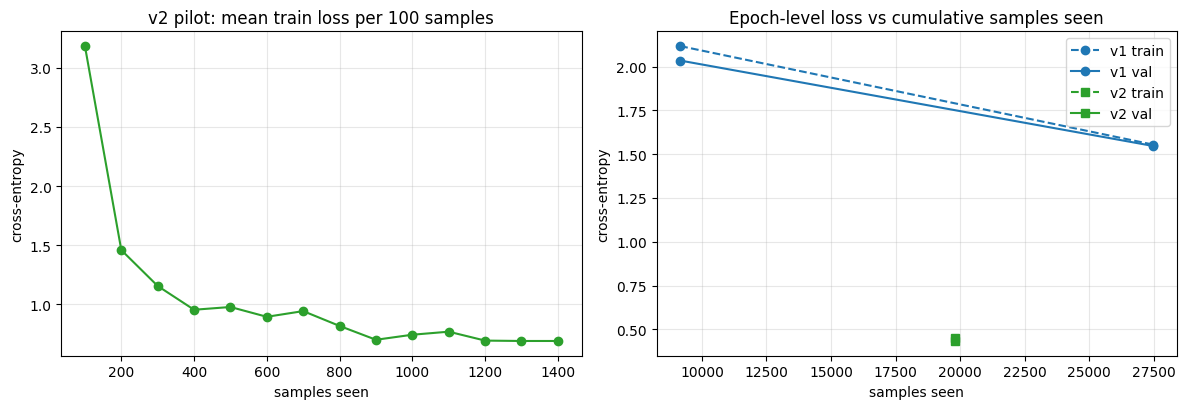

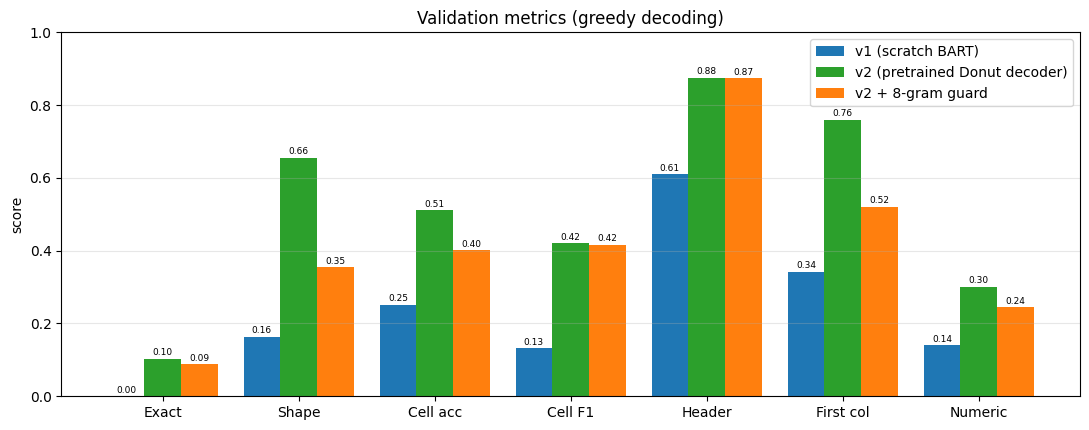

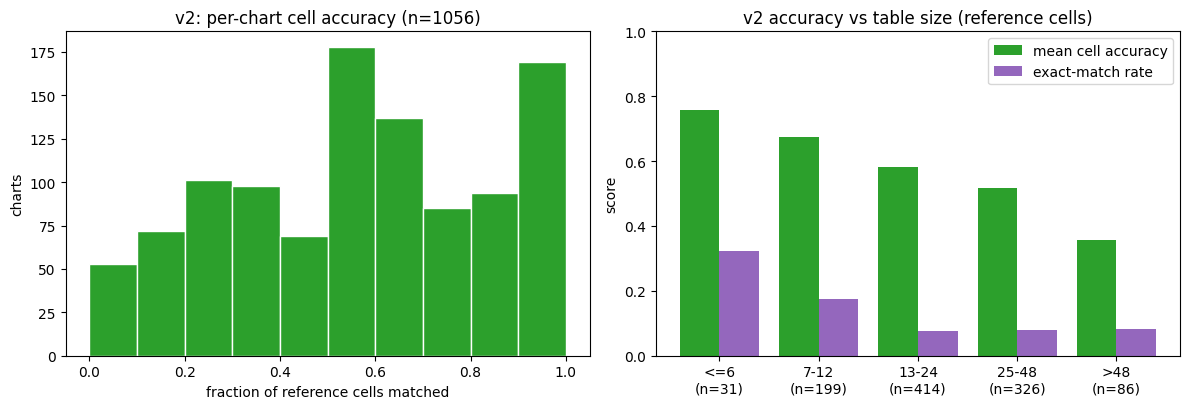

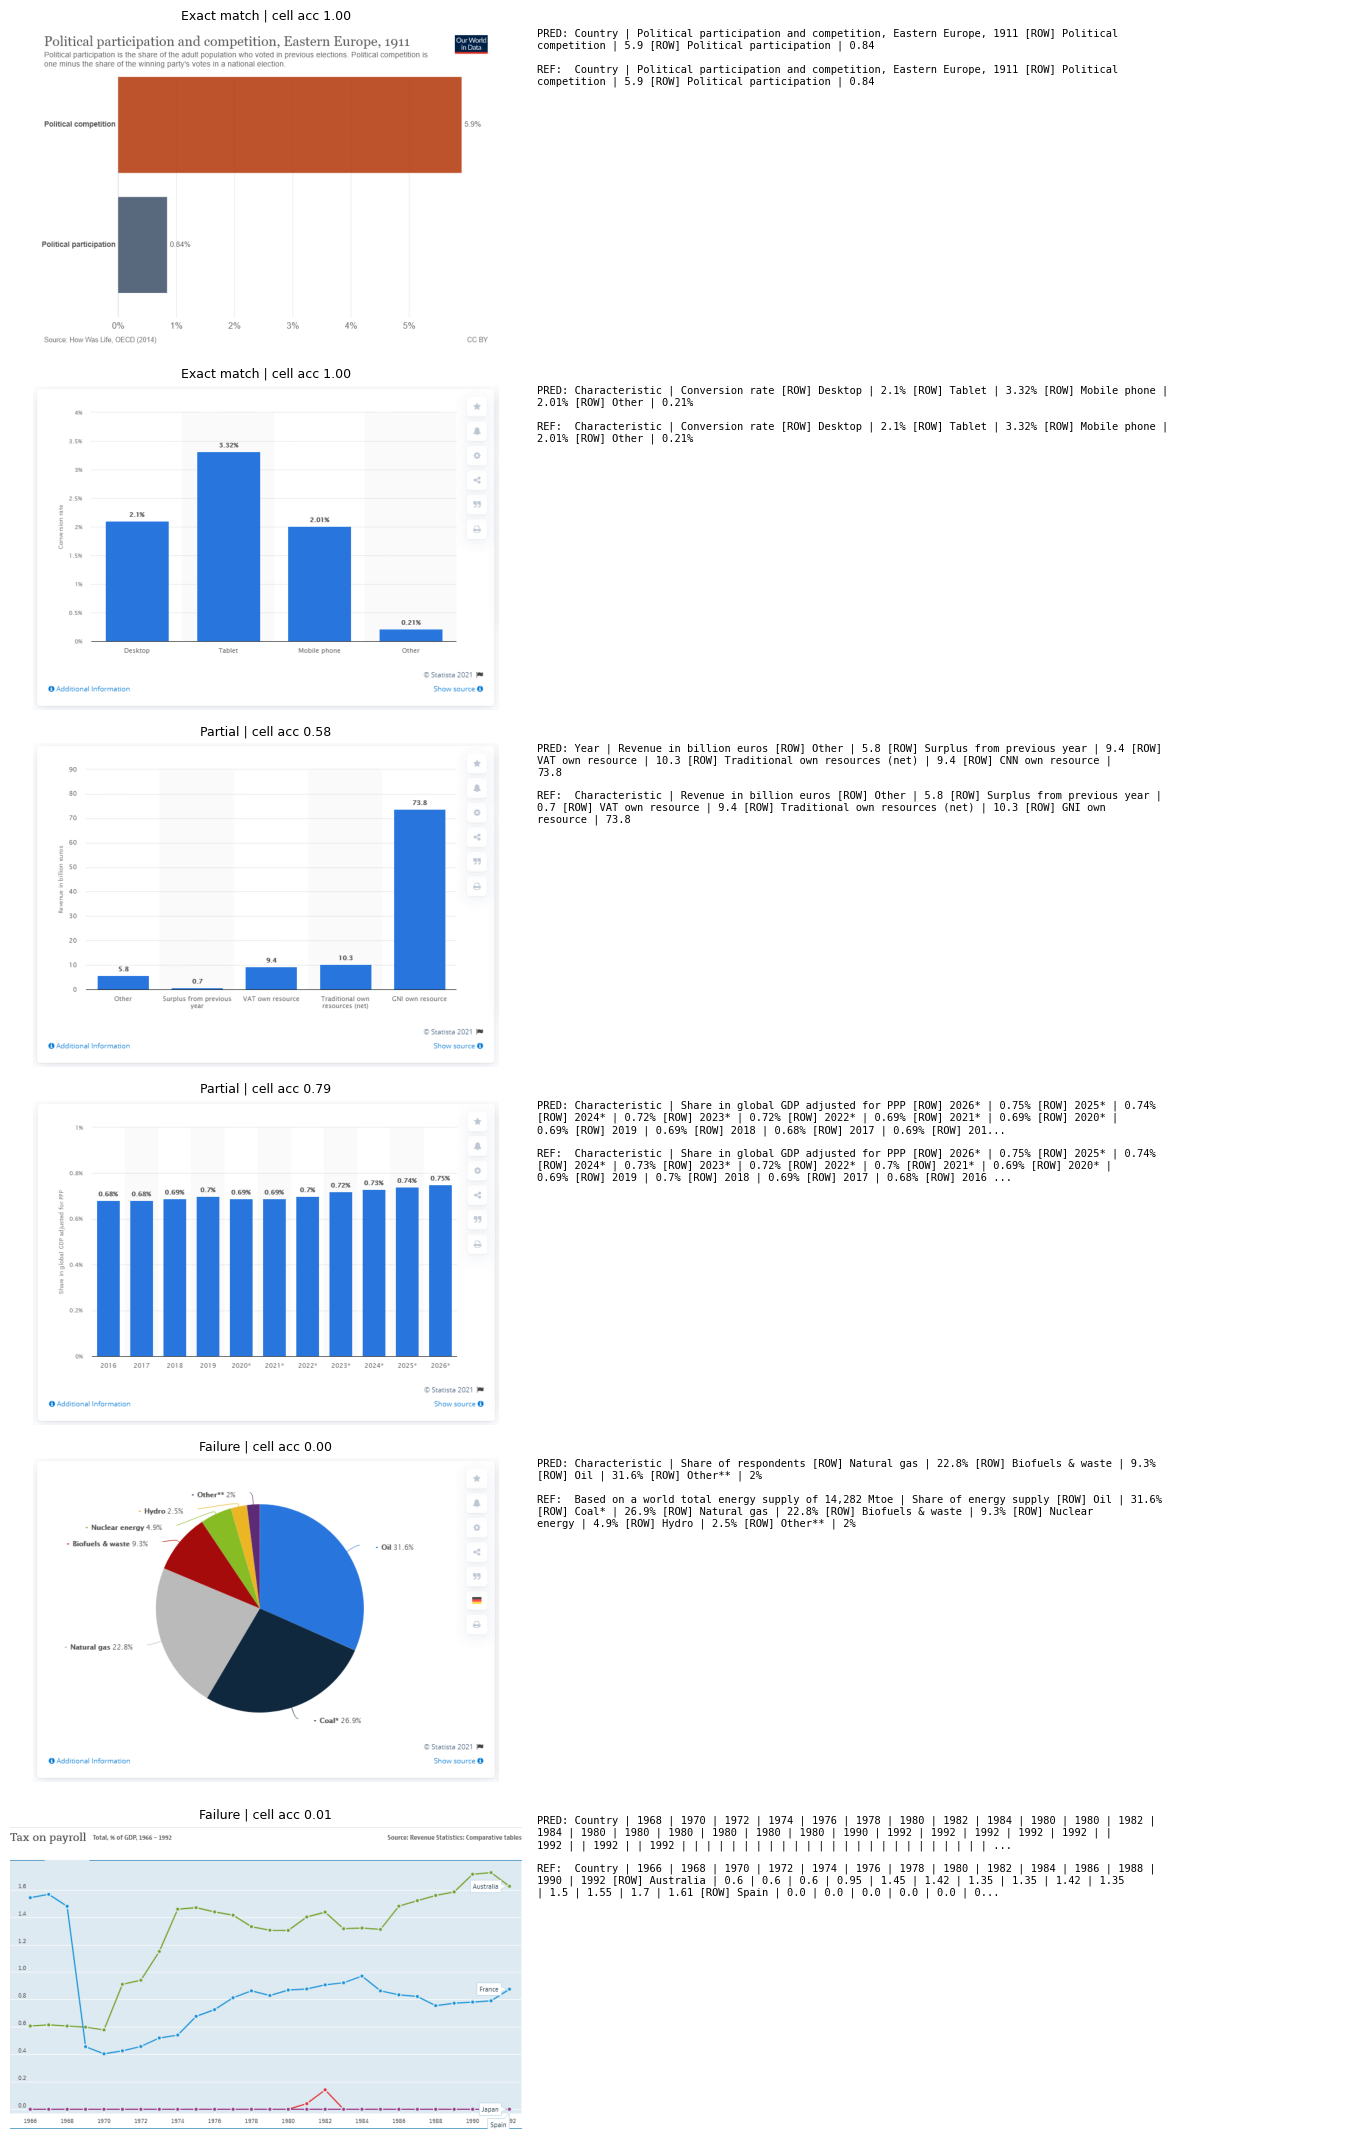

Saved: ['fig1_loss_curves.png', 'fig3_accuracy_distribution.png', 'fig2_metric_comparison.png', 'fig4_sample_generations.png']


In [31]:
import os, json, textwrap, numpy as np, matplotlib.pyplot as plt
from PIL import Image

OUT = "/kaggle/working"
V1_EPOCH3 = None   # optional later: (train_loss, val_loss) of v1 epoch 3; leave None for now

# ---------------- Figure 1: loss curves ----------------
pilot_x = list(range(100, 1500, 100))
pilot_y = [3.1843, 1.4587, 1.1551, 0.9539, 0.9771, 0.8942, 0.9424, 0.8168,
           0.6999, 0.7426, 0.7683, 0.6929, 0.6897, 0.6897]
v1_x, v1_tr, v1_va = [9158, 27474], [2.1170, 1.5546], [2.0344, 1.5469]
if V1_EPOCH3:
    v1_x.append(45790); v1_tr.append(V1_EPOCH3[0]); v1_va.append(V1_EPOCH3[1])
v2_x = [1496 + 18317]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(pilot_x, pilot_y, "o-", color="tab:green")
ax[0].set(title="v2 pilot: mean train loss per 100 samples", xlabel="samples seen", ylabel="cross-entropy")
ax[0].grid(alpha=.3)
ax[1].plot(v1_x, v1_tr, "o--", color="tab:blue", label="v1 train")
ax[1].plot(v1_x, v1_va, "o-", color="tab:blue", label="v1 val")
ax[1].plot(v2_x, [0.4502], "s--", color="tab:green", label="v2 train")
ax[1].plot(v2_x, [0.4340], "s-", color="tab:green", label="v2 val")
ax[1].set(title="Epoch-level loss vs cumulative samples seen", xlabel="samples seen", ylabel="cross-entropy")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_loss_curves.png", dpi=200); plt.show()

# ---------------- Figure 2: metric comparison ----------------
names = ["Exact", "Shape", "Cell acc", "Cell F1", "Header", "First col", "Numeric"]
v1m = [0.0009, 0.1641, 0.2516, 0.1317, 0.6094, 0.3425, 0.1396]
v2m = [0.1032, 0.6553, 0.5119, 0.4199, 0.8752, 0.7602, 0.3014]
gdm = [0.0881, 0.3542, 0.4012, 0.4167, 0.8743, 0.5210, 0.2444]
x, w = np.arange(len(names)), 0.27
plt.figure(figsize=(11, 4.4))
for k, (vals, lab, col) in enumerate([(v1m, "v1 (scratch BART)", "tab:blue"),
                                      (v2m, "v2 (pretrained Donut decoder)", "tab:green"),
                                      (gdm, "v2 + 8-gram guard", "tab:orange")]):
    b = plt.bar(x + (k - 1) * w, vals, w, label=lab, color=col)
    plt.bar_label(b, fmt="%.2f", fontsize=6.5, padding=1)
plt.xticks(x, names); plt.ylabel("score"); plt.ylim(0, 1.0)
plt.title("Validation metrics (greedy decoding)"); plt.legend(); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_metric_comparison.png", dpi=200); plt.show()

# ---------------- per-chart scores for figures 3 and 4 ----------------
pred = json.load(open(f"{OUT}/val_predictions_v2_plain.json"))
path = {os.path.basename(a): a for a, _ in val_dataset.samples}
for s in pred:
    r = compare(parse_table(s["pred"]), parse_table(s["ref"]))
    s["acc"], s["exact"], s["n_ref"] = r["match"] / max(r["n_ref"], 1), bool(r["exact"]), r["n_ref"]
acc = np.array([s["acc"] for s in pred]); nref = np.array([s["n_ref"] for s in pred])
exact = np.array([s["exact"] for s in pred])

# ---------------- Figure 3: per-chart accuracy and table size ----------------
edges = [0, 6, 12, 24, 48, 10**6]; labels = ["<=6", "7-12", "13-24", "25-48", ">48"]
bin_id = np.digitize(nref, edges[1:-1], right=True)
mean_acc = [acc[bin_id == b].mean() if (bin_id == b).any() else 0 for b in range(5)]
ex_rate = [exact[bin_id == b].mean() if (bin_id == b).any() else 0 for b in range(5)]
cnt = [int((bin_id == b).sum()) for b in range(5)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(acc, bins=10, range=(0, 1), color="tab:green", edgecolor="white")
ax[0].set(title=f"v2: per-chart cell accuracy (n={len(acc)})", xlabel="fraction of reference cells matched", ylabel="charts")
xb = np.arange(5)
ax[1].bar(xb - 0.2, mean_acc, 0.4, label="mean cell accuracy", color="tab:green")
ax[1].bar(xb + 0.2, ex_rate, 0.4, label="exact-match rate", color="tab:purple")
ax[1].set_xticks(xb); ax[1].set_xticklabels([f"{l}\n(n={c})" for l, c in zip(labels, cnt)])
ax[1].set(title="v2 accuracy vs table size (reference cells)", ylabel="score", ylim=(0, 1)); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_accuracy_distribution.png", dpi=200); plt.show()

# ---------------- Figure 4: sample generations ----------------
order = np.argsort(acc)
ex_idx = [i for i in range(len(pred)) if exact[i]]
picks = []
if ex_idx: picks += [("Exact match", ex_idx[0]), ("Exact match", ex_idx[len(ex_idx) // 2])]
picks += [("Partial", int(order[len(order) // 2])), ("Partial", int(order[int(len(order) * .75)])),
          ("Failure", int(order[0])), ("Failure", int(order[5]))]
fig, axes = plt.subplots(len(picks), 2, figsize=(14, 3.6 * len(picks)), gridspec_kw={"width_ratios": [1, 1.6]})
wrap = lambda t: "\n".join(textwrap.wrap(t[:260] + ("..." if len(t) > 260 else ""), 95))
for row, (tag, i) in zip(axes, picks):
    s = pred[i]
    row[0].imshow(Image.open(path[s["image"]]).convert("RGB")); row[0].axis("off")
    row[0].set_title(f"{tag} | cell acc {s['acc']:.2f}", fontsize=9)
    row[1].axis("off")
    row[1].text(0, 1, "PRED: " + wrap(s["pred"]) + "\n\nREF:  " + wrap(s["ref"]),
                va="top", family="monospace", fontsize=7.5)
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_sample_generations.png", dpi=200); plt.show()
print("Saved:", [f for f in os.listdir(OUT) if f.startswith("fig")])